# Digital Image Processing Lab
## Lab Task 04 – Geometric Transformations with Custom Inputs

**Student Name:** Sakeena Bano

**Roll Number:** 2024_SE_29

**Department:** Software Engineering

**Semester:** 5th Semester

**Lab Instructor:** Engr. Fahad Nisar

**Session:** 2024-28 (SE)

# Step 1: Import Libraries

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

print("All libraries imported successfully.")

All libraries imported successfully.


# Step 2: Validate and Display Original Image:

Image loaded successfully.
Width: 1254
Height: 1254
Array Shape: (1254, 1254, 3)
Data Type: uint8


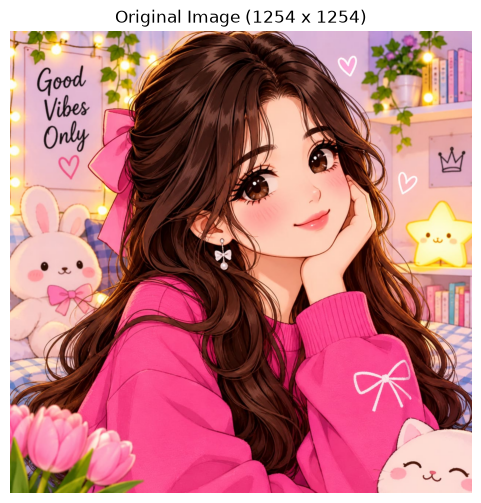

In [2]:
image_path = "img.jpeg"

if not os.path.exists(image_path):
    raise FileNotFoundError("Image file not found.")

original = cv2.imread(image_path, cv2.IMREAD_COLOR)

if original is None:
    raise ValueError("Image could not be decoded.")

if original.size == 0:
    raise ValueError("Image is empty.")

height, width = original.shape[:2]

if height <= 0 or width <= 0:
    raise ValueError("Invalid image dimensions.")

original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

print("Image loaded successfully.")
print("Width:", width)
print("Height:", height)
print("Array Shape:", original.shape)
print("Data Type:", original.dtype)
plt.figure(figsize=(7, 6))
plt.imshow(original_rgb)
plt.title(f"Original Image ({width} x {height})")
plt.axis("off")
plt.show()

# Step 4:  Create Reusable Display and Save Function

In [3]:
MAX_PIXELS = 25_000_000
MAX_DIMENSION = 10000

def transform(image, operation, **params):

    if image is None or not isinstance(image, np.ndarray):
        raise ValueError("Invalid input image!")

    if image.ndim != 3 or image.shape[2] != 3:
        raise ValueError("Image must have 3 color channels!")

    h, w = image.shape[:2]

    if h == 0 or w == 0:
        raise ValueError("Image dimensions cannot be zero!")

    def finite_number(value, name):
        if isinstance(value, (bool, np.bool_)):
            raise ValueError(name + " must be numeric!")

        try:
            value = float(value)
        except (TypeError, ValueError):
            raise ValueError(name + " must be numeric!")

        if not math.isfinite(value):
            raise ValueError(name + " must be finite!")

        return value

    def integer_coordinate(value, name):
        if isinstance(value, (bool, np.bool_)):
            raise ValueError(name + " must be an integer!")

        if not isinstance(value, (int, np.integer)):
            raise ValueError(name + " must be an integer!")

        return int(value)

    def check_size(new_w, new_h):
        if new_w < 1 or new_h < 1:
            raise ValueError("Output dimensions must be at least one pixel!")

        if new_w > MAX_DIMENSION or new_h > MAX_DIMENSION:
            raise ValueError("Output dimension exceeds maximum limit!")

        if new_w * new_h > MAX_PIXELS:
            raise ValueError("Output image is too large!")

    allowed = {
        "scale": {"sx", "sy", "interpolation"},
        "crop": {"left", "top", "right", "bottom"},
        "flip": {"direction"},
        "translate": {"tx", "ty"},
        "rotate": {"angle", "expand"}
    }

    if operation not in allowed:
        raise ValueError("Unknown operation!")

    missing = allowed[operation] - params.keys()

    if missing:
        raise ValueError("Missing parameters: " + str(missing))

    if set(params) != allowed[operation]:
        raise ValueError("Unexpected parameters supplied!")

    if operation == "scale":

        sx = finite_number(params["sx"], "sx")
        sy = finite_number(params["sy"], "sy")

        if sx <= 0 or sy <= 0:
            raise ValueError("Scale factors must be greater than zero!")

        methods = {
            "nearest": cv2.INTER_NEAREST,
            "bilinear": cv2.INTER_LINEAR,
            "bicubic": cv2.INTER_CUBIC,
            "lanczos": cv2.INTER_LANCZOS4
        }

        method = params["interpolation"]

        if method not in methods:
            raise ValueError("Unsupported interpolation method!")

        new_w = int(round(w * sx))
        new_h = int(round(h * sy))

        check_size(new_w, new_h)

        return cv2.resize(
            image, (new_w, new_h),
            interpolation=methods[method]
        )

    elif operation == "crop":

        left = integer_coordinate(params["left"], "left")
        top = integer_coordinate(params["top"], "top")
        right = integer_coordinate(params["right"], "right")
        bottom = integer_coordinate(params["bottom"], "bottom")

        if not (0 <= left < right <= w):
            raise ValueError("Invalid horizontal crop coordinates!")

        if not (0 <= top < bottom <= h):
            raise ValueError("Invalid vertical crop coordinates!")

        result = image[top:bottom, left:right].copy()

        if result.size == 0:
            raise ValueError("Crop produced an empty image!")

        return result

    elif operation == "flip":

        directions = {
            "horizontal": 1,
            "vertical": 0,
            "both": -1
        }

        direction = params["direction"]

        if direction not in directions:
            raise ValueError("Unsupported flip direction!")

        return cv2.flip(image.copy(), directions[direction])

    elif operation == "translate":

        tx = finite_number(params["tx"], "tx")
        ty = finite_number(params["ty"], "ty")

        matrix = np.float32([
            [1, 0, tx],
            [0, 1, ty]
        ])

        return cv2.warpAffine(
            image, matrix, (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=(0, 0, 0)
        )

    elif operation == "rotate":

        angle = finite_number(params["angle"], "angle")
        expand = params["expand"]

        if not isinstance(expand, (bool, np.bool_)):
            raise ValueError("Expand must be True or False!")

        center = (w / 2, h / 2)

        matrix = cv2.getRotationMatrix2D(center, angle, 1.0)

        if expand:
            cos_value = abs(matrix[0, 0])
            sin_value = abs(matrix[0, 1])

            new_w = int(math.ceil(h * sin_value + w * cos_value))
            new_h = int(math.ceil(h * cos_value + w * sin_value))

            check_size(new_w, new_h)

            matrix[0, 2] += (new_w - w) / 2
            matrix[1, 2] += (new_h - h) / 2

        else:
            new_w, new_h = w, h

        return cv2.warpAffine(
            image, matrix, (new_w, new_h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=(0, 0, 0)
        )
        

In [4]:
print("Reusable transform function created successfully!")

Reusable transform function created successfully!


# Step 5:Display Transformation Results

In [5]:
def show_result(title, result, parameters):

    result_rgb = cv2.cvtColor(
        result, cv2.COLOR_BGR2RGB
    )

    h, w = result.shape[:2]

    plt.figure(figsize=(6, 5))
    plt.imshow(result_rgb)
    plt.title(
        f"{title}\nParameters: {parameters}\nSize: {w} x {h}"
    )
    plt.axis("off")
    plt.show()

# Step 6:  Scaling / Resizing Transformation

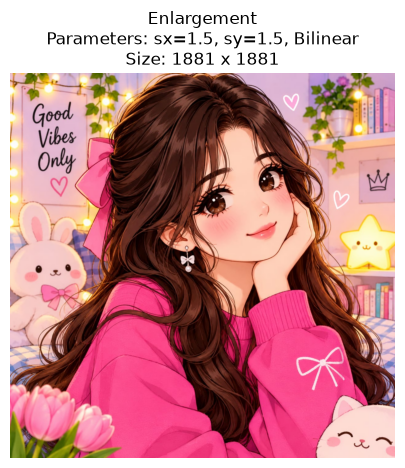

In [6]:
enlarged = transform(
    original,
    "scale",
    sx=1.5,
    sy=1.5,
    interpolation="bilinear"
)

show_result(
    "Enlargement",
    enlarged,
    "sx=1.5, sy=1.5, Bilinear"
)

# 6(b) Reduction

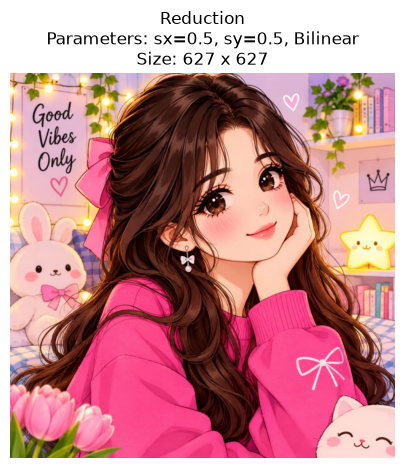

In [7]:
reduced = transform(
    original,
    "scale",
    sx=0.5,
    sy=0.5,
    interpolation="bilinear"
)

show_result(
    "Reduction",
    reduced,
    "sx=0.5, sy=0.5, Bilinear"
)

# 6(c) Non-Proportional Scaling

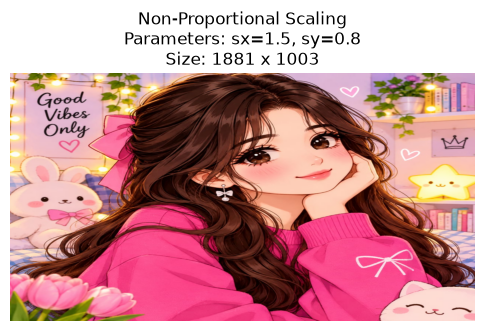

In [8]:
non_proportional = transform(
    original,
    "scale",
    sx=1.5,
    sy=0.8,
    interpolation="bilinear"
)

show_result(
    "Non-Proportional Scaling",
    non_proportional,
    "sx=1.5, sy=0.8"
)

# Observation:

Scaling changes the dimensions of an image. Enlargement increases image size, while reduction decreases it. Non-proportional scaling changes the aspect ratio and may distort the image

# Step 7: Cropping

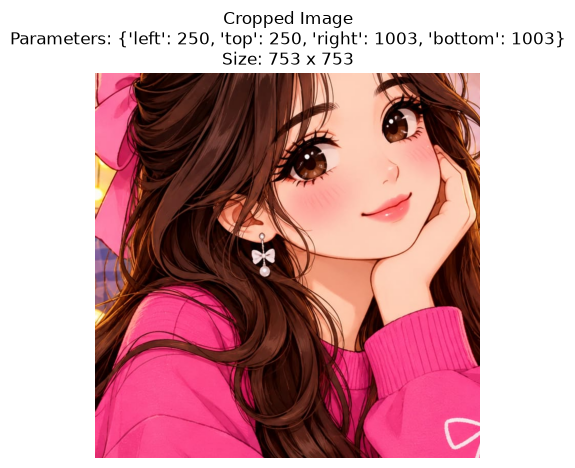

In [9]:
crop_left = int(width * 0.20)
crop_top = int(height * 0.20)
crop_right = int(width * 0.80)
crop_bottom = int(height * 0.80)

cropped = transform(
    original,
    "crop",
    left=crop_left,
    top=crop_top,
    right=crop_right,
    bottom=crop_bottom
)

show_result(
    "Cropped Image",
    cropped,
    {
        "left": crop_left,
        "top": crop_top,
        "right": crop_right,
        "bottom": crop_bottom
    }
)

# Observation
Cropping removes the selected outer regions of an image and keeps only the specified rectangular area.

# Step 8: Flipping

# 8(a) Horizontal Flip


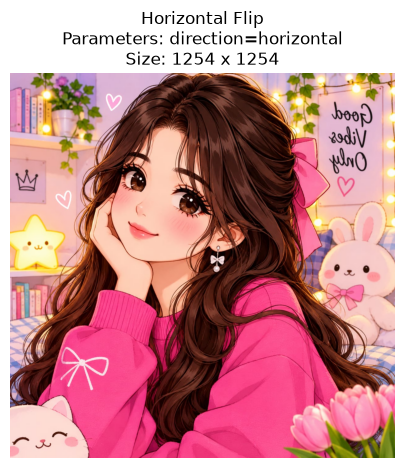

In [10]:
horizontal_flip = transform(
    original,
    "flip",
    direction="horizontal"
)

show_result("Horizontal Flip", horizontal_flip, "direction=horizontal")

# 8(b) Vertical Flip

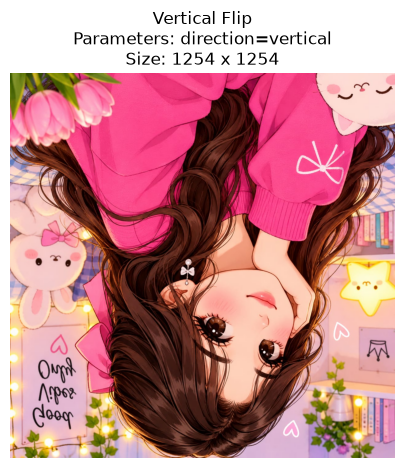

In [11]:
vertical_flip = transform(
    original,
    "flip",
    direction="vertical"
)

show_result("Vertical Flip", vertical_flip, "direction=vertical")

# 8(c) Both Directions

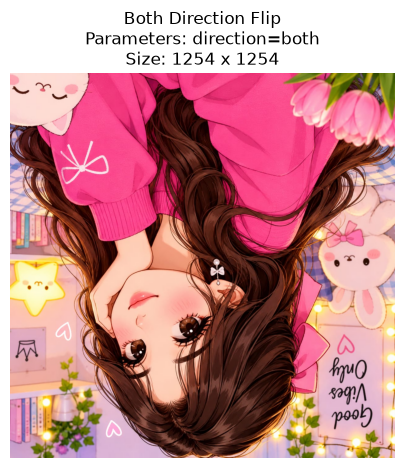

In [12]:
both_flip = transform(
    original,
    "flip",
    direction="both"
)

show_result("Both Direction Flip", both_flip, "direction=both")

# Observation:

Horizontal flipping reverses the image from left to right. Vertical flipping reverses it from top to bottom. Both flipping performs both transformations.

# Step 9: Translation

# 9(a): Positive Translation

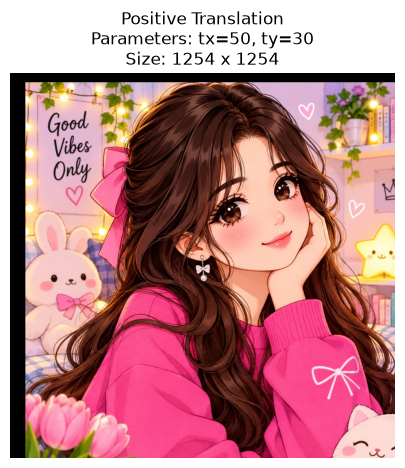

In [13]:
positive_shift = transform(
    original,
    "translate",
    tx=50,
    ty=30
)

show_result(
    "Positive Translation",
    positive_shift,
    "tx=50, ty=30"
)

# 9(b): Negative Translation

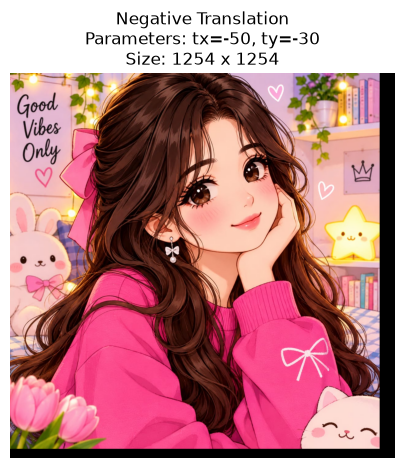

In [14]:
negative_shift = transform(
    original,
    "translate",
    tx=-50,
    ty=-30
)

show_result(
    "Negative Translation",
    negative_shift,
    "tx=-50, ty=-30"
)

# Observation :

Translation shifts an image horizontally and vertically without changing the canvas size. Some image parts may be clipped, while newly exposed background areas appear black.

# Step 10: Rotation

# 10(a): Positive Rotation

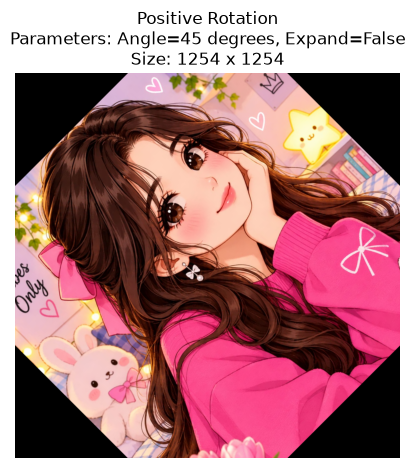

In [15]:
positive_rotation = transform(
    original,
    "rotate",
    angle=45,
    expand=False
)

show_result(
    "Positive Rotation",
    positive_rotation,
    "Angle=45 degrees, Expand=False"
)

# 10(b): Negative Rotation

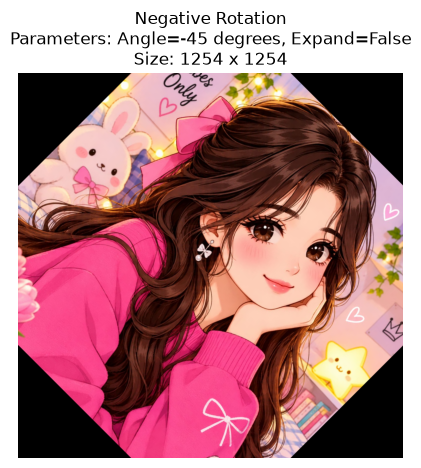

In [16]:
negative_rotation = transform(
    original,
    "rotate",
    angle=-45,
    expand=False
)

show_result(
    "Negative Rotation",
    negative_rotation,
    "Angle=-45 degrees, Expand=False"
)

# 10(c): Rotation with Expanded Canvas

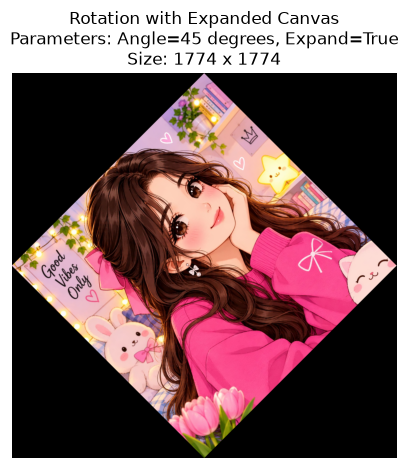

In [17]:
expanded_rotation = transform(
    original,
    "rotate",
    angle=45,
    expand=True
)

show_result(
    "Rotation with Expanded Canvas",
    expanded_rotation,
    "Angle=45 degrees, Expand=True"
)

# 10(c): Rotation with Expanded Canvas

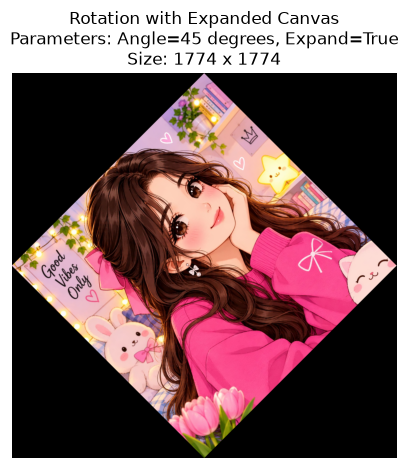

In [18]:
expanded_rotation = transform(
    original,
    "rotate",
    angle=45,
    expand=True
)

show_result(
    "Rotation with Expanded Canvas",
    expanded_rotation,
    "Angle=45 degrees, Expand=True"
)

# Observation :

Rotation turns an image around its centre. In OpenCV, positive angles rotate counter-clockwise and negative angles rotate clockwise. Canvas expansion prevents the rotated image from being clipped by the original canvas boundaries.

# Step 11:Affine Transformation

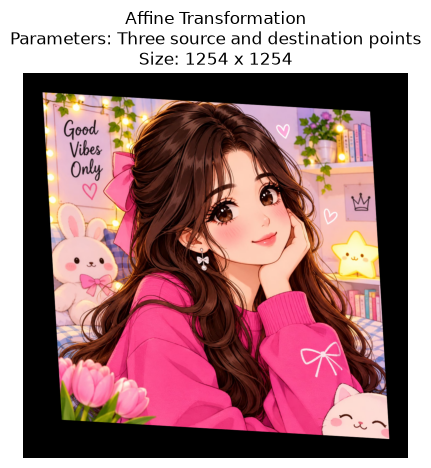

In [19]:
# Affine Transformation

src_points = np.float32([
    [0, 0],
    [width - 1, 0],
    [0, height - 1]
])

dst_points = np.float32([
    [width * 0.05, height * 0.05],
    [width * 0.90, height * 0.10],
    [width * 0.10, height * 0.90]
])

matrix = cv2.getAffineTransform(
    src_points,
    dst_points
)

affine_result = cv2.warpAffine(
    original,
    matrix,
    (width, height)
)

show_result(
    "Affine Transformation",
    affine_result,
    "Three source and destination points"
)

# Observation
Affine transformation changes the image geometry using three point correspondences. It can produce effects such as rotation, scaling, shearing, and translation.

# Step 11: Interpolation Comparison

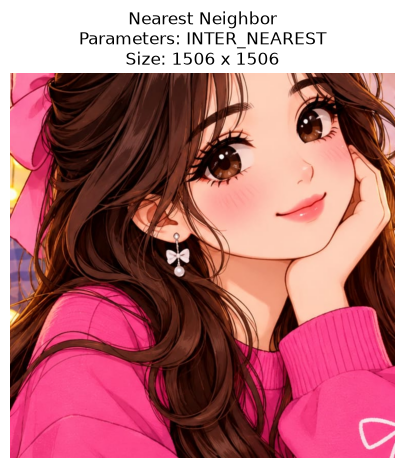

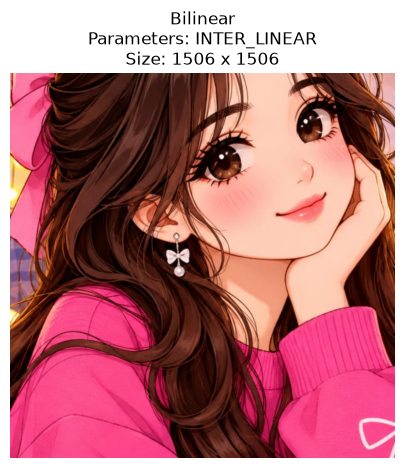

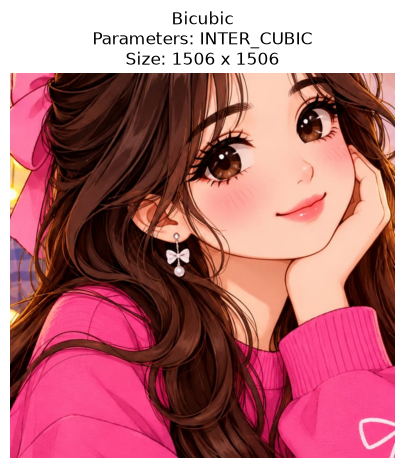

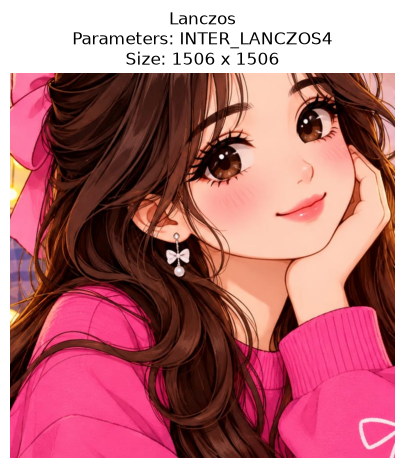

In [20]:
patch = cropped

nearest = cv2.resize(
    patch,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_NEAREST
)

bilinear = cv2.resize(
    patch,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_LINEAR
)

bicubic = cv2.resize(
    patch,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_CUBIC
)

lanczos = cv2.resize(
    patch,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_LANCZOS4
)

show_result("Nearest Neighbor", nearest, "INTER_NEAREST")
show_result("Bilinear", bilinear, "INTER_LINEAR")
show_result("Bicubic", bicubic, "INTER_CUBIC")
show_result("Lanczos", lanczos, "INTER_LANCZOS4")

# Observation
Nearest Neighbor is fast but may produce pixelated results. Bilinear produces smoother images, while Bicubic and Lanczos generally provide better quality and detail during enlargement.

# Step 12: ## Custom Transformation Using User-Defined Parameters

This step allows the user to select a transformation and provide custom parameters.

     CUSTOM IMAGE TRANSFORMATION

Available Operations:
1. scale
2. crop
3. flip
4. translate
5. rotate



Enter operation:  scale
Enter horizontal scale factor (sx):  1.5
Enter vertical scale factor (sy):  2



Interpolation methods:
nearest, bilinear, bicubic, lanczos


Enter interpolation method:  bilinear


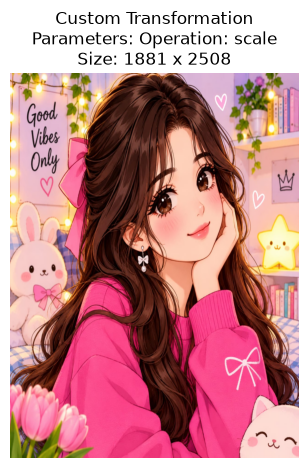

In [21]:
def run_custom_transform():

    try:
        print("===================================")
        print("     CUSTOM IMAGE TRANSFORMATION")
        print("===================================")

        print("\nAvailable Operations:")
        print("1. scale")
        print("2. crop")
        print("3. flip")
        print("4. translate")
        print("5. rotate")

        operation = input("\nEnter operation: ").strip().lower()

        if operation == "scale":

            sx = float(input("Enter horizontal scale factor (sx): "))
            sy = float(input("Enter vertical scale factor (sy): "))

            print("\nInterpolation methods:")
            print("nearest, bilinear, bicubic, lanczos")

            interpolation = input(
                "Enter interpolation method: "
            ).strip().lower()

            result = transform(
                original,
                "scale",
                sx=sx,
                sy=sy,
                interpolation=interpolation
            )

        elif operation == "crop":

            left = int(input("Enter left coordinate: "))
            top = int(input("Enter top coordinate: "))
            right = int(input("Enter right coordinate: "))
            bottom = int(input("Enter bottom coordinate: "))

            result = transform(
                original,
                "crop",
                left=left,
                top=top,
                right=right,
                bottom=bottom
            )

        elif operation == "flip":

            print("\nFlip directions:")
            print("horizontal, vertical, both")

            direction = input(
                "Enter flip direction: "
            ).strip().lower()

            result = transform(
                original,
                "flip",
                direction=direction
            )

        elif operation == "translate":

            tx = float(input("Enter horizontal shift (tx): "))
            ty = float(input("Enter vertical shift (ty): "))

            result = transform(
                original,
                "translate",
                tx=tx,
                ty=ty
            )

        elif operation == "rotate":

            angle = float(input("Enter rotation angle: "))

            expand_text = input(
                "Expand canvas? (yes/no): "
            ).strip().lower()

            if expand_text not in ["yes", "no"]:
                raise ValueError("Please enter yes or no.")

            result = transform(
                original,
                "rotate",
                angle=angle,
                expand=(expand_text == "yes")
            )

        else:
            raise ValueError("Unknown operation selected!")

        show_result(
            "Custom Transformation",
            result,
            f"Operation: {operation}"
        )

        return result

    except (ValueError, TypeError, OverflowError) as error:

        print("\nError:", error)
        print("Please correct your input and try again.")

        return None


custom_result = run_custom_transform()

# Step 13: Invalid Input Testing


In [25]:
# Test 1: Invalid scaling factor
try:
    transform(original, "scale", sx=0, sy=1.5,
              interpolation="bilinear")
    print("Test 1: FAIL")
except (ValueError, TypeError):
    print("Test 1: PASS - Invalid scaling factor rejected")

# Test 2: Invalid crop coordinates
try:
    transform(original, "crop",
              left=200, top=200,
              right=50, bottom=50)
    print("Test 2: FAIL")
except (ValueError, TypeError):
    print("Test 2: PASS - Invalid crop rejected")

# Test 3: Invalid flip direction
try:
    transform(original, "flip", direction="diagonal")
    print("Test 3: FAIL")
except (ValueError, TypeError):
    print("Test 3: PASS - Invalid flip direction rejected")

# Test 4: Invalid translation value
try:
    transform(original, "translate", tx=float("nan"), ty=30)
    print("Test 4: FAIL")
except (ValueError, TypeError):
    print("Test 4: PASS - Invalid translation rejected")

# Test 5: Invalid rotation value
try:
    transform(original, "rotate", angle=float("inf"), expand=True)
    print("Test 5: FAIL")
except (ValueError, TypeError):
    print("Test 5: PASS - Invalid rotation rejected")

Test 1: PASS - Invalid scaling factor rejected
Test 2: PASS - Invalid crop rejected
Test 3: PASS - Invalid flip direction rejected
Test 4: PASS - Invalid translation rejected
Test 5: PASS - Invalid rotation rejected


# Step 14: Identity Transformation Checks

In [23]:
identity_scale = transform(
    original,
    "scale",
    sx=1,
    sy=1,
    interpolation="bilinear"
)

identity_translation = transform(
    original,
    "translate",
    tx=0,
    ty=0
)

identity_rotation = transform(
    original,
    "rotate",
    angle=0,
    expand=False
)

identity_tests = [
    ("Scale (1,1)", np.array_equal(original, identity_scale)),
    ("Translation (0,0)", np.array_equal(original, identity_translation)),
    ("Rotation (0)", np.array_equal(original, identity_rotation))
]

identity_table = pd.DataFrame(
    identity_tests,
    columns=["Identity Test", "Actual Behaviour"]
)

identity_table["Expected Behaviour"] = "No change"
identity_table["Result"] = identity_table["Actual Behaviour"].apply(
    lambda x: "PASS" if x else "FAIL"
)

identity_table = identity_table[
    ["Identity Test", "Expected Behaviour", "Actual Behaviour", "Result"]
]

display(identity_table)

,Identity Test,Expected Behaviour,Actual Behaviour,Result
0,"Scale (1,1)",No change,True,PASS
1,"Translation (0,0)",No change,True,PASS
2,Rotation (0),No change,True,PASS


# Step 15: Save All Transformed Images

In [24]:
output_folder = "Lab04_Results"
os.makedirs(output_folder, exist_ok=True)

results = {
    "enlarged": enlarged,
    "reduced": reduced,
    "non_proportional": non_proportional,

    "horizontal_flip": horizontal_flip,
    "vertical_flip": vertical_flip,
    "both_flip": both_flip,

    "positive_translation": positive_shift,

    "expanded_rotation": expanded_rotation
}

# Add other results only if their variables exist
optional_results = [
    "negative_shift",
    "positive_rotation",
    "negative_rotation"
]

for name in optional_results:
    if name in globals():
        results[name] = globals()[name]

for name, image in results.items():
    file_path = os.path.join(output_folder, name + ".png")
    cv2.imwrite(file_path, image)

print("All available transformed images saved successfully!")
print("Total images saved:", len(results))
print("Folder:", output_folder)

All available transformed images saved successfully!
Total images saved: 11
Folder: Lab04_Results


# Short conceptual Explanation
1. Image Coordinates vs Array Indexing

Image coordinates represent horizontal and vertical positions, while array indexing uses rows and columns. In NumPy, the first index represents the row (y-coordinate), and the second index represents the column (x-coordinate).

2. Aspect Ratio Distortion

Aspect ratio describes the relationship between image width and height. When horizontal and vertical scaling factors are different, the image may become stretched or compressed.

3. Rotation Canvas Expansion

Canvas expansion increases the output dimensions to accommodate the rotated image and prevent clipping of its corners.

4. Translation Clipping

Translation moves an image while keeping the original canvas size. Parts moving outside the canvas are clipped, and exposed areas are filled with the background color.